In [1]:
#The usual preamble
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

import tensorflow as tf
from scipy import signal

#for your homework
np.random.seed(37509116)
tf.random.set_seed(37509116)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


100000
4.096010485786843
[0.00000000e+00 4.09605145e-05 8.19210289e-05 ... 4.09592856e+00
 4.09596953e+00 4.09601049e+00]


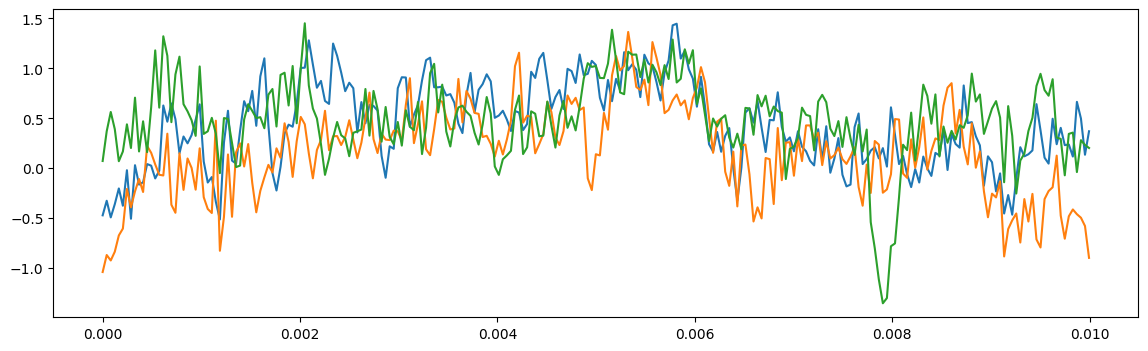

In [3]:
#load the sample Brain data
#3 channels from GPi, each in microvolts.  sampling at 24.414kHz
micro123 = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/micro123.csv', names=['ch1','ch2','ch3'])
nDims=3
samplingFrequency = 24414
nPoints = len(micro123)
maxTime = nPoints/samplingFrequency
ts_index = np.linspace(start= 0 ,stop=maxTime, num= nPoints)

#scale the range.  scale separately for each of the 3 data channels
from sklearn.preprocessing import StandardScaler   #use standard normal (mean 0, std 1) rather than min/max scaler here
scaler = StandardScaler()
scaler.fit(micro123)
micro123_scaled = scaler.transform(micro123)
dfMic = pd.DataFrame(micro123_scaled, index = ts_index)  #make a dataframe

print(nPoints)
print(maxTime)
print(ts_index)
plt.figure(figsize=(14,4))
plt.plot(dfMic[0:.01]);

In [4]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = 4 * int(samplingFrequency/1000.0)  #4 msec
gen = TimeseriesGenerator(dfMic.values, dfMic.values, length =predict_length , batch_size=1)
gen[0][0].shape

(1, 96, 3)

In [15]:
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Permute, AveragePooling2D, Concatenate
from tensorflow.keras.layers import Dense, Flatten, Reshape, Conv2D, LayerNormalization, SimpleRNN
from tensorflow.keras.layers import MaxPooling2D, GlobalAveragePooling2D, ConvLSTM2D, LSTM, Input
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.callbacks import EarlyStopping

In [16]:
#Create a subclass of keras.Model that learns auto-encoding
class AutoEncoderModel(Model):
    def train_step(self, data):
        # Unpack the data. Its structure depends on your model and
        # on what you pass to `fit()`.
        x, y = data
        y = x ###for autoencoder; ignore target supplied by timeseriesgenerator; this is the only change to the code.

        with tf.GradientTape() as tape:
            y_pred = self(x, training=True)  # Forward pass. ## We dont want to freeze the weights. Hence training=true
            # Compute the loss value
            # (the loss function is configured in `compile()`)
            loss = self.compiled_loss(y, y_pred, regularization_losses=self.losses)

        # Compute gradients
        trainable_vars = self.trainable_variables
        gradients = tape.gradient(loss, trainable_vars)
        # Update weights
        self.optimizer.apply_gradients(zip(gradients, trainable_vars))
        # Update metrics (includes the metric that tracks the loss)
        self.compiled_metrics.update_state(y, y_pred)
        # Return a dict mapping metric names to current value
        return {m.name: m.result() for m in self.metrics}

In [17]:
#build a simple linear autoencoder network
n_hidden_units1 = 8
batch_size1 = 1

input_layer = Input(shape=(predict_length, nDims), name='input_layer')
flatten_layer = Flatten()(input_layer)  #have to flatten the 96x3 input in order to learn the eigenvectors
encode_layer = Dense(units=n_hidden_units1, activation='linear', use_bias=False, name='encode')(flatten_layer)
decode_layer = Dense(units=nDims*predict_length, activation='linear', use_bias=False, name='decode')(encode_layer)
reshape_layer = Reshape((predict_length, nDims))(decode_layer)
output_layer = reshape_layer

#use the AutoencoderModel
model1 = AutoEncoderModel(inputs = input_layer, outputs = output_layer, name ='model1')  #have to explicitly tell it the inputs and outputs
model1.compile(optimizer='adam', loss='mse')
model1.summary()



Model: "model1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encode (Dense)                  │ (None, 8)              │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decode (Dense)                  │ (None, 288)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 96, 3)          │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,608 (18.00 KB)

 Trainable params: 4,608 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/usr/local/lib/python3.12/dist-packages/keras/src/backend/tensorflow/trainer.py:671: UserWarning: `model.compiled_loss()` is deprecated. Instead, use `model.compute_loss(x, y, y_pred, sample_weight, training)`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/backend/tensorflow/trainer.py:646: UserWarning: `model.compiled_metrics()` is deprecated. Instead, use e.g.:
```
for metric in self.metrics:
    metric.update_state(y, y_pred)
```

  return self._compiled_metrics_update_state(


99904/99904 ━━━━━━━━━━━━━━━━━━━━ 159s 2ms/step - loss: 0.0020
Epoch 2/5
99904/99904 ━━━━━━━━━━━━━━━━━━━━ 154s 2ms/step - loss: -0.0049
Epoch 3/5
99904/99904 ━━━━━━━━━━━━━━━━━━━━ 152s 2ms/step - loss: -0.0011
Epoch 4/5
99904/99904 ━━━━━━━━━━━━━━━━━━━━ 153s 2ms/step - loss: -0.0051
Epoch 5/5
99904/99904 ━━━━━━━━━━━━━━━━━━━━ 155s 2ms/step - loss: 0.0014


<Axes: >

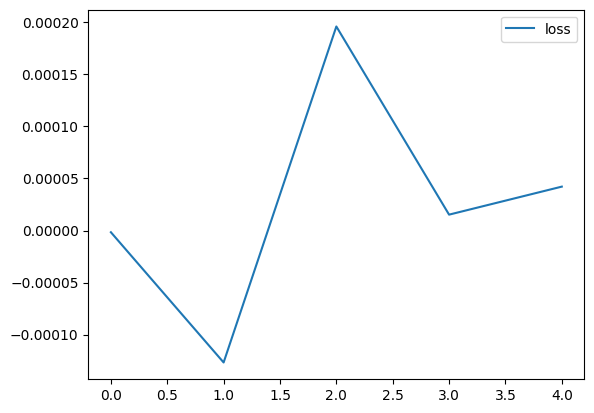

In [18]:
#we can use gen (timeseriesgenerator) here because AutoEncoderModel will ignore the output y and use the input as the target instead.
model1.fit(gen,epochs=5)
losses = pd.DataFrame(model1.history.history)
losses.plot()

(96, 3, 8)


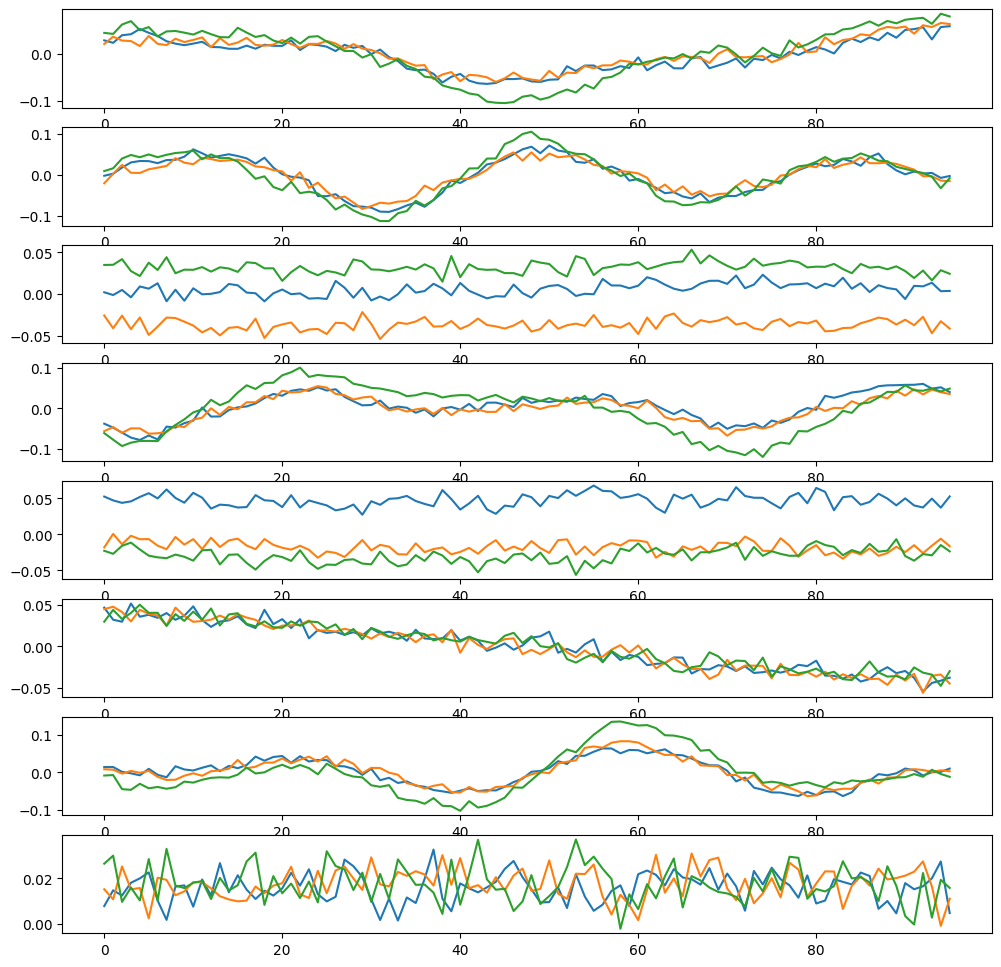

In [19]:
w1 = np.asarray(model1.weights[0])
ws1 = np.reshape(w1, (predict_length, nDims, n_hidden_units1))
print(ws1.shape)
fig, ax = plt.subplots(n_hidden_units1, 1, figsize=(12,12))
for h in range(n_hidden_units1):
  ax[h].plot(ws1[:,:,h])

In [20]:
ch1 = dfMic[1].values
ln = predict_length * int(len(ch1)/predict_length)
ln -= predict_length  #for safety
#turn into blocks of predict_length data points
x2 = np.reshape(ch1[:ln], (-1,predict_length))
np.testing.assert_equal(ch1[0:predict_length], x2[0,:])  #check that reshape worked correctly

#calculate for all the other offsets and add those too (out of order)
for offset in range(1,predict_length):
  x2 = np.concatenate((x2,np.reshape(ch1[offset:ln+offset], (-1,predict_length))))

#make a gaussian window
win = np.linspace(-2,2, predict_length)
win = np.exp(-win * win)
win = win / np.sum(win)

#apply the window to the data
y2 = win * x2

In [21]:
#build a simple linear autoencoder network
n_hidden_units2 = 8
batch_size = 10

input_layer = Input(shape=(predict_length,), name='input_layer')
encode_layer = Dense(units=n_hidden_units2, activation='linear', use_bias=False, name='encode')(input_layer)
decode_layer = Dense(units=predict_length, activation='linear', use_bias=False, name='decode')(encode_layer)
output_layer = decode_layer

#here we use the regular keras.Model because we will set the output manually
model2 = Model(inputs = input_layer, outputs = output_layer, name ='model2')  #have to explicitly tell it the inputs and outputs
model2.compile(optimizer='adam', loss='mse')
model2.summary()


Model: "model2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encode (Dense)                  │ (None, 8)              │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decode (Dense)                  │ (None, 96)             │           768 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,536 (6.00 KB)

 Trainable params: 1,536 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - loss: 0.0040
Epoch 2/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step - loss: 1.7326e-05
Epoch 3/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 1.2410e-05
Epoch 4/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 1.1987e-05
Epoch 5/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 1.2007e-05


<Axes: >

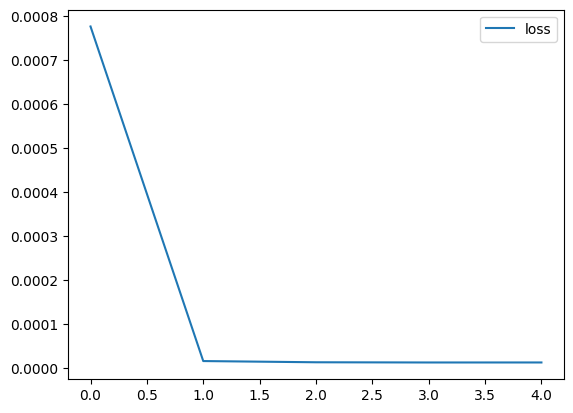

In [22]:
#we have created the outputs that we want; do not have to use the AutoEncoderModel
model2.fit(x2,y2,epochs=5, batch_size = batch_size)
losses = pd.DataFrame(model2.history.history)
losses.plot()

(96, 8)


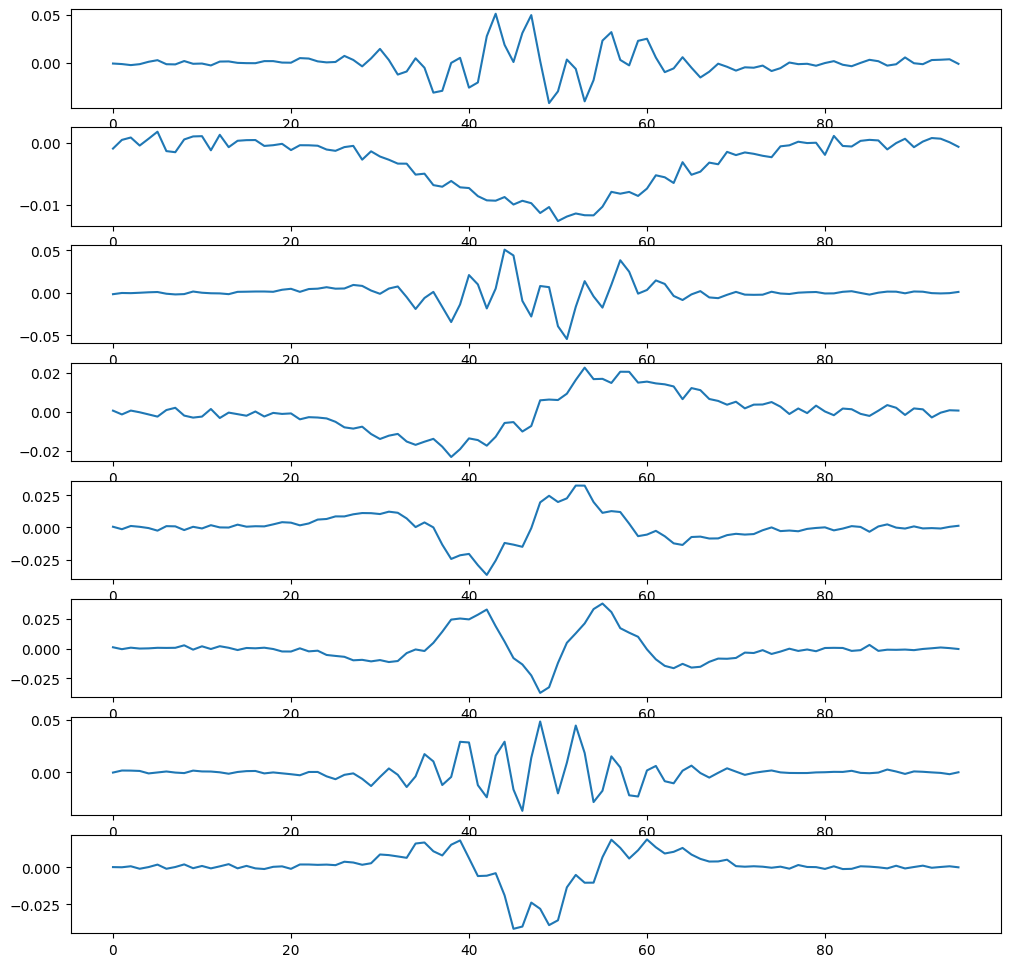

In [23]:
ws2 = np.asarray(model2.weights[0])
print(ws2.shape)
fig, ax = plt.subplots(n_hidden_units2, 1, figsize=(12,12))
for h in range(n_hidden_units2):
  ax[h].plot(ws2[:,h])
  #ax[h].plot(win *ws2[:,h])

In [24]:
#make a gaussian window
win = np.linspace(-2,2, predict_length)
win = np.exp(-win * win)
win = win / np.sum(win)

#put all 3 channels together
for c in range(nDims):
  ch = dfMic[c].values
  ln = predict_length * int(len(ch)/predict_length)
  ln -= predict_length  #for safety
  #turn into blocks of predict_length data points
  xc = np.reshape(ch[:ln], (-1,predict_length))

  #calculate for all the other offsets and add those to the end
  for offset in range(1,predict_length):
    xc = np.concatenate((xc,np.reshape(ch[offset:ln+offset], (-1,predict_length))))

  #apply the window to this channel
  yc = win * xc

  #concatenate horizontally for each of the input axes
  if c==0:
    x3 = xc
    y3 = yc
  else:
    x3 = np.concatenate((x3,xc), axis=1)
    y3 = np.concatenate((y3,yc), axis=1)


In [25]:
#autoencoder network to compress the 96x3 flattened input data
n_hidden_units3a = 20

input_layer = Input(shape=(predict_length*nDims,), name='input_layer')
encode_layer = Dense(units=n_hidden_units3a, activation='linear', use_bias=False, name='encode')(input_layer)
decode_layer = Dense(units=predict_length*nDims, activation='linear', use_bias=False, name='decode')(encode_layer)
output_layer = decode_layer

model3a = Model(inputs = input_layer, outputs = output_layer, name ='model3a')  #have to explicitly tell it the inputs and outputs
model3a.compile(optimizer='adam', loss='mse')
model3a.summary()


Model: "model3a"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encode (Dense)                  │ (None, 20)             │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decode (Dense)                  │ (None, 288)            │         5,760 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,520 (45.00 KB)

 Trainable params: 11,520 (45.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 16s 1ms/step - loss: 0.0030
Epoch 2/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 1.9602e-05
Epoch 3/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 1.4424e-05
Epoch 4/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 1.4192e-05
Epoch 5/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 1.4317e-05


<Axes: >

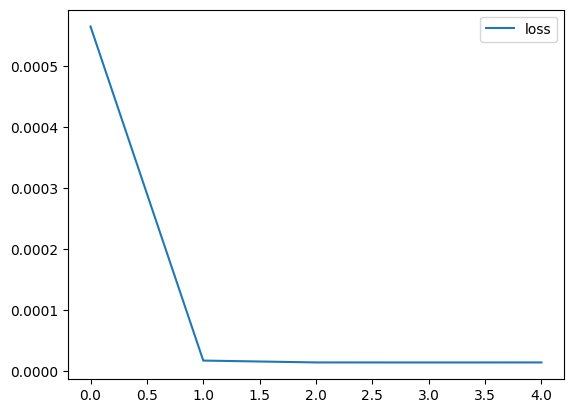

In [26]:
model3a.fit(x3,y3,epochs=5, batch_size = 10)
losses = pd.DataFrame(model3a.history.history)
losses.plot()

(288, 20)


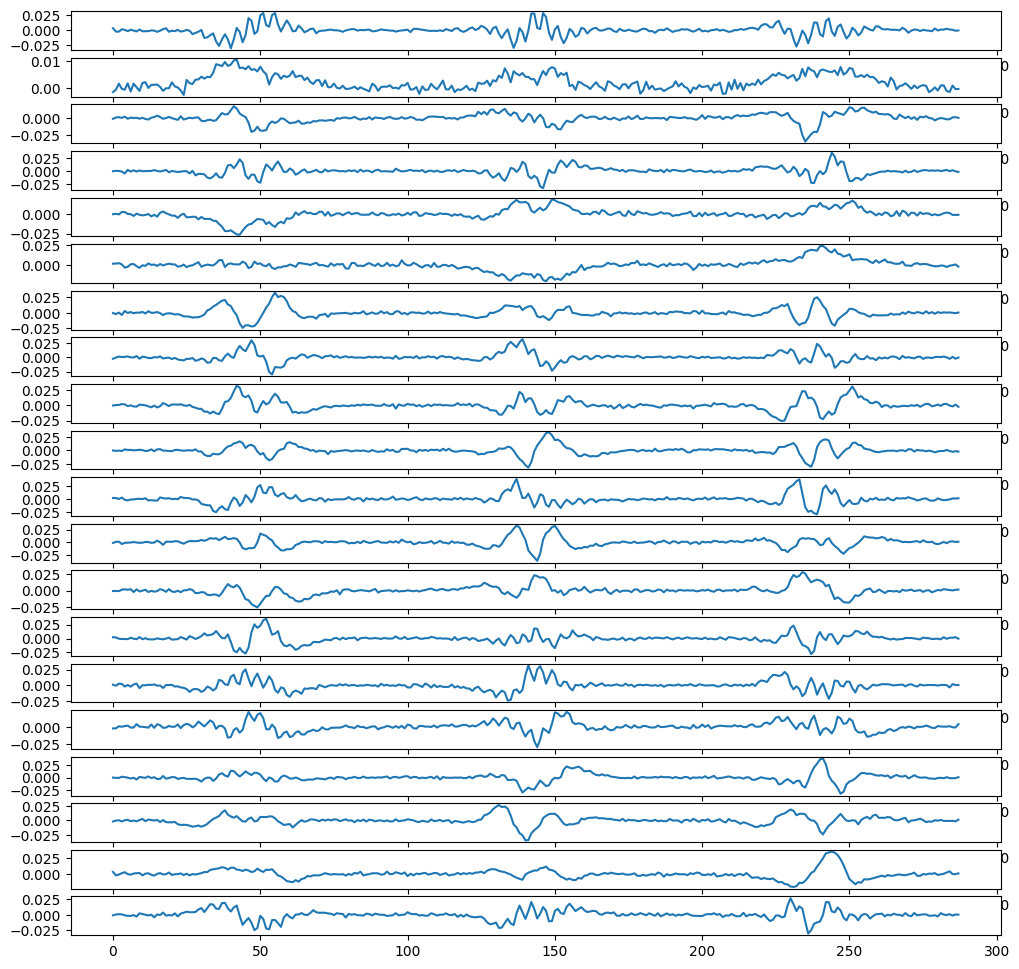

In [27]:
ws3 = np.asarray(model3a.weights[0])
print(ws3.shape)
fig, ax = plt.subplots(n_hidden_units3a, 1, figsize=(12,12))
for h in range(n_hidden_units3a):
  ax[h].plot(ws3[:,h])

In [28]:
def volterraExpand(data, volterra_order):
  nData, volterra_memory = data.shape

  #calculate the length of the kernel.  1(constant term) + memory(linear term) + memory^2 in this case
  filter_length = 1
  for n in range(1, volterra_order+1):
    filter_length = filter_length + volterra_memory**n
  y = np.zeros((nData, filter_length))  #set the first ones to zero so outputs line up

  #now run the volterra kernel over the input to generate the output
  for t in range(0,nData):
      xt = data[t,:]
      xn = [1]  #constant term in volterra expansion
      inp = [1]
      for n in range(1,volterra_order+1):  #loop over the power (order) of volterra terms
        xn = np.outer(xn,xt).ravel()    #this creates all the products x(t-i)x(t-j)...x(t-w) for the n'th order term
        inp = np.append(inp,xn)        #include all the terms, constant+linear+secondorder+...
                                      #each term has length volterra_memory**n including all possible cross-products
      y[t,:] = inp

  return y


In [29]:
#filter the original data with the linear encoder weights to get y=Wx
x3a = x3 @ ws3

#now build a set of volterra kernels on these
# in this case, volterra_memory will be the number of linear components from the encoder
volterra_order = 2   #maximum polynomial order; more than 2 is usually unwieldy
                    #note that volterra_order=1 just gives a linear filter
xv = volterraExpand(x3a, volterra_order)  #this is sigma[y] = sigma[Wx]

#the polynomial Volterra terms can have very large values, so scale them down
scaler2 = StandardScaler()
scaler.fit(xv)
x3b = scaler.transform(xv)

x3b[:,1]=1  #keep the constant term
nt, n_volterra_inputs = x3b.shape
print(x3b.shape)


(99840, 421)


In [30]:
#build a simple linear autoencoder network on top of the volterra expasnsion
n_hidden_units3b = 50

input_layer = Input(shape=(n_volterra_inputs,), name='input_layer')
encode_layer = Dense(units=n_hidden_units3b, activation='linear', use_bias=False, name='encode')(input_layer)
decode_layer = Dense(units=n_volterra_inputs, activation='linear', use_bias=False, name='decode')(encode_layer)
output_layer = decode_layer

model3b = Model(inputs = input_layer, outputs = output_layer, name ='model3b')  #have to explicitly tell it the inputs and outputs
model3b.compile(optimizer='adam', loss='mse')
model3b.summary()


Model: "model3b"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 421)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encode (Dense)                  │ (None, 50)             │        21,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decode (Dense)                  │ (None, 421)            │        21,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,100 (164.45 KB)

 Trainable params: 42,100 (164.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 16s 2ms/step - loss: 0.5913
Epoch 2/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 14s 1ms/step - loss: 0.4751
Epoch 3/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 0.4746
Epoch 4/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 0.4742
Epoch 5/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 0.4752


<Axes: >

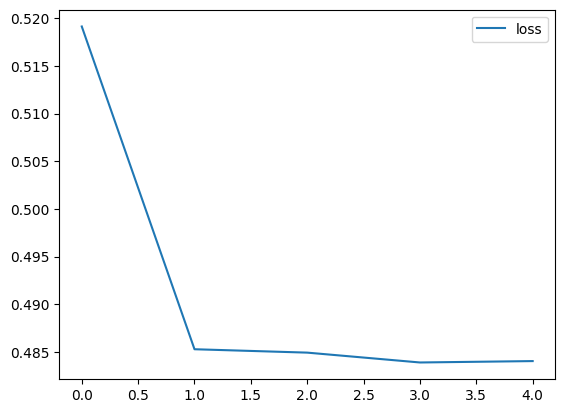

In [31]:
model3b.fit(x3b,x3b,epochs=5, batch_size = 10)
losses = pd.DataFrame(model3b.history.history)
losses.plot()

In [32]:
#apply volterra encoder to volterra data to get U sigma[Wx]
wvs = np.asarray(model3b.weights[0])  #this is the encoder layer weights
print(wvs.shape)
x_volterra_encoded = x3b @ wvs
nt, n_volterra_encoded = x_volterra_encoded.shape
print(x_volterra_encoded.shape)


(421, 50)
(99840, 50)


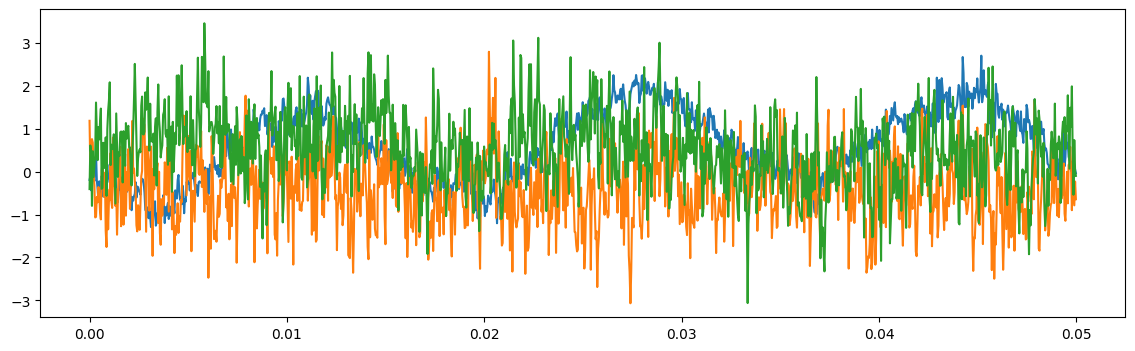

In [64]:
#load more sample Brain data (as before, you have to copy micro456.csv to your google drive)
#3 channels from GPi, each in microvolts.  sampling at 24.414kHz
micro456 = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/micro456.csv', names=['ch4','ch5','ch6'])
nDims456=3
samplingFrequency = 24414
nPoints = len(micro456)
np.testing.assert_equal(nPoints, len(micro123))
maxTime = nPoints/samplingFrequency
ts_index = np.linspace(start= 0 ,stop=maxTime, num= nPoints)

#eigenvector transform the data to remove correlations
w,v = np.linalg.eig(micro456.T @ micro456)
micro456 = micro456 @ v

#scale the range.  scale separately for each of the data channels
scaler2 = StandardScaler()
scaler2.fit(micro456)
micro456_scaled = scaler2.transform(micro456)

micro456_scaled = micro456_scaled[int(predict_length/2):,:]  #shift so we predict the point in the middle
micro456_scaled = micro456_scaled[:len(x_volterra_encoded),:]  #has to be the same length as the predicting dataset
dfMic456 = pd.DataFrame(micro456_scaled, index = ts_index[:len(x_volterra_encoded)])

plt.figure(figsize=(14,4))
plt.plot(dfMic456[0:.05]);

In [65]:
#build a simple linear network on top of the volterra compression

input_layer = Input(shape=(n_volterra_encoded,), name='input_layer')
fit_layer = Dense(units=nDims456, activation='linear', name='encode')(input_layer)
output_layer = fit_layer

model4 = Model(inputs = input_layer, outputs = output_layer, name ='model4')  #have to explicitly tell it the inputs and outputs
model4.compile(optimizer='adam', loss='mse')
model4.summary()


Model: "model4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encode (Dense)                  │ (None, 3)              │           153 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 153 (612.00 B)

 Trainable params: 153 (612.00 B)

 Non-trainable params: 0 (0.00 B)

In [66]:
print(x_volterra_encoded.shape)
print(micro456_scaled.shape)

(99840, 50)
(99840, 3)


Epoch 1/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 1.6564
Epoch 2/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step - loss: 1.0130
Epoch 3/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step - loss: 1.0130
Epoch 4/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 1.0130
Epoch 5/5
9984/9984 ━━━━━━━━━━━━━━━━━━━━ 15s 1ms/step - loss: 1.0130


<Axes: >

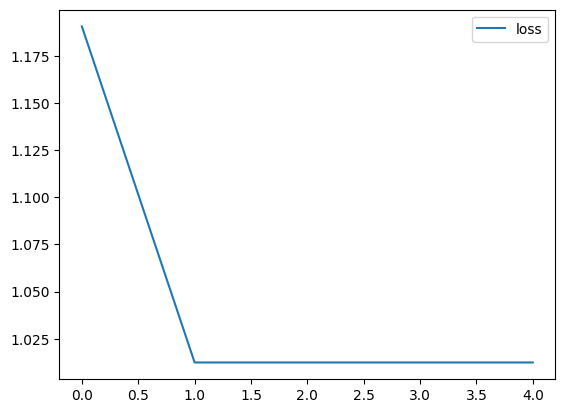

In [67]:
model4.fit(x_volterra_encoded, micro456_scaled,epochs=5, batch_size = 10)
losses = pd.DataFrame(model4.history.history)
losses.plot()

In [68]:
#calculate the predicted outputs.  This gives A*U*sigma[Wx]
micro456_predict = model4.predict(x_volterra_encoded)

3120/3120 ━━━━━━━━━━━━━━━━━━━━ 3s 953us/step


Output 0 has r -0.0011 and p 0.7381
Output 1 has r 0.0054 and p 0.0885
Output 2 has r 0.0040 and p 0.2009


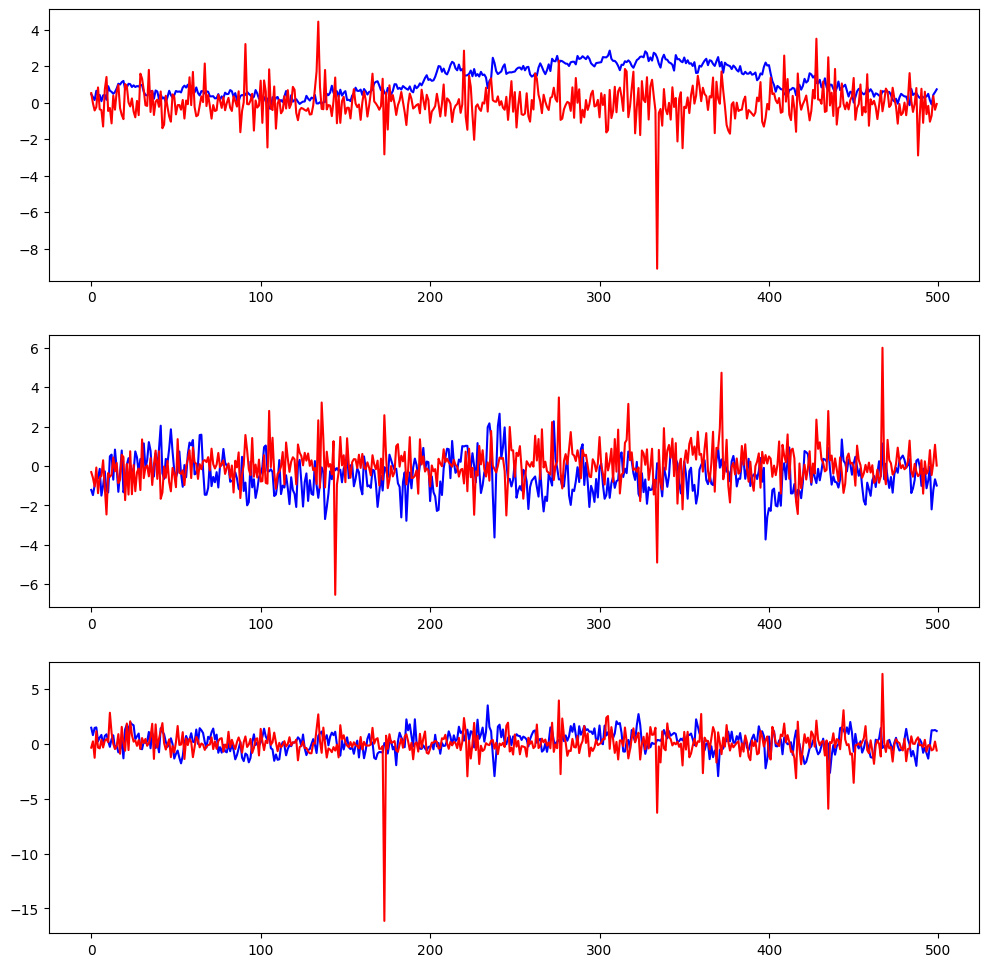

In [69]:
#apply scaling to the prediction, so we can match the scaled inputs
scaler3 = StandardScaler()
scaler3.fit(micro456_predict)
micro456_predict_scaled = scaler3.transform(micro456_predict)

fig,ax=plt.subplots(nDims456,1,figsize=(12,12))
t1 = 2000
t2 = 2500
for s in range(nDims456):
  ax[s].plot(micro456_scaled[t1:t2,s],'b')
  ax[s].plot(micro456_predict_scaled[t1:t2,s],'r')
  slope, intercept, r_value, p_value, std_err = sp.stats.linregress(micro456_scaled[:,s], micro456_predict_scaled[:,s])
  print("Output %d has r %.4f and p %.4f" % (s, r_value, p_value))



In [70]:
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Permute, AveragePooling2D, Concatenate
from tensorflow.keras.layers import Dense, Flatten, Reshape, Conv2D, LayerNormalization, SimpleRNN
from tensorflow.keras.layers import MaxPooling2D, GlobalAveragePooling2D, ConvLSTM2D, LSTM, Input
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.callbacks import EarlyStopping

Model: "model4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder input (InputLayer)      │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 20)             │        46,548 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 3)              │        10,471 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,019 (222.73 KB)

 Trainable params: 57,019 (222.73 KB)

 Non-trainable params: 0 (0.00 B)

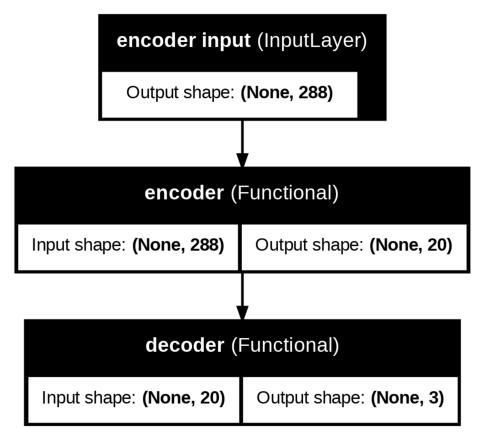

In [71]:
#build a simple autoencoder network for 2D data using a nonlinear encoder/decoder
n_hidden_units = 20
num_features = x3.shape[1]   # number of columns / features

#using the functional API so that I can separate the encoder and decoder
encode_input = Input(shape=(num_features,), name='encoder input')
encode_layer1 = Dense(units=128, activation='linear', name='encode1')(encode_input)
encode_layer2 = Dense(units=64, activation='linear', name='encode2')(encode_layer1)
encode_layer3 = Dense(units=n_hidden_units, activation='linear', name='encode3')(encode_layer2)
encode_output = encode_layer3
encoder4 = Model(encode_input,encode_output, name='encoder')  #separate model for the encoder
# we can throw out the rest of the network after training if we want.
decode_input = Input(shape = (n_hidden_units,))  #this is the same as the encoder output
decode_layer3 = Dense(units=n_hidden_units, activation='linear', name='decode3')(decode_input)
decode_layer2 = Dense(units=64, activation='linear', name='decode2')(decode_layer3)
decode_layer1 = Dense(units=128, activation='linear', name='decode1')(decode_layer2)
decode_output = Dense(units=3, activation='linear', name='output')(decode_layer1)

decoder4 = Model(decode_input, decode_output, name='decoder')  #model for the decoder

#build the stacked model
hidden_units = encoder4(encode_input)
full_output = decoder4(hidden_units)
model4 = Model(encode_input, full_output, name ='model4')  #this is the one we will train

opt = tf.keras.optimizers.Adam(learning_rate=3e-4)

model4.compile(optimizer='adam', loss='mse')
model4.summary()
plot_model(model4, to_file='model.png', show_shapes=True, show_layer_names=True)
plt.figure(figsize=(6,8))  # Adjust the figure size as needed
plt.imshow(plt.imread('model.png'))
plt.axis('off')
plt.show()

Epoch 1/60
2496/2496 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 1.0526 - val_loss: 0.9640
Epoch 2/60
2496/2496 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 1.0130 - val_loss: 0.9658
Epoch 3/60
2496/2496 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 1.0109 - val_loss: 0.9699
Epoch 4/60
2496/2496 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 1.0103 - val_loss: 0.9718
Epoch 5/60
2496/2496 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 1.0101 - val_loss: 0.9722
Epoch 6/60
2496/2496 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 1.0099 - val_loss: 0.9733
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 1.


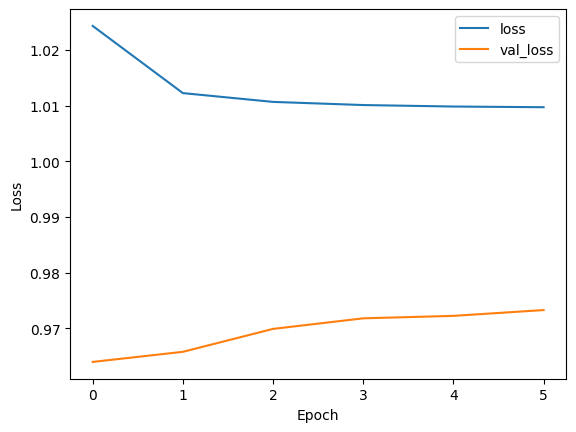

In [72]:
es = EarlyStopping(
    monitor='val_loss',      # what to watch
    patience=5,              # epochs with no improvement before stopping
    restore_best_weights=True,  # roll back to best weights
    min_delta=0.0,           # minimum change to qualify as an improvement
    verbose=1
)


# 2. Train with callback
history = model4.fit(
    x3,
    micro456_scaled,
    epochs=60,
    batch_size=32,
    validation_split=0.2,
    callbacks=[es],
    verbose=1
)

# 3. Plot training & validation loss
losses = pd.DataFrame(history.history)
ax = losses[['loss', 'val_loss']].plot()
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
plt.show()

In [74]:
#calculate the predicted outputs.  This gives A*U*sigma[Wx]
micro456_predict = model4.predict(x3)

3120/3120 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step


Output 0 has r 0.0039 and p 0.2140
Output 1 has r -0.0035 and p 0.2637
Output 2 has r 0.0034 and p 0.2761


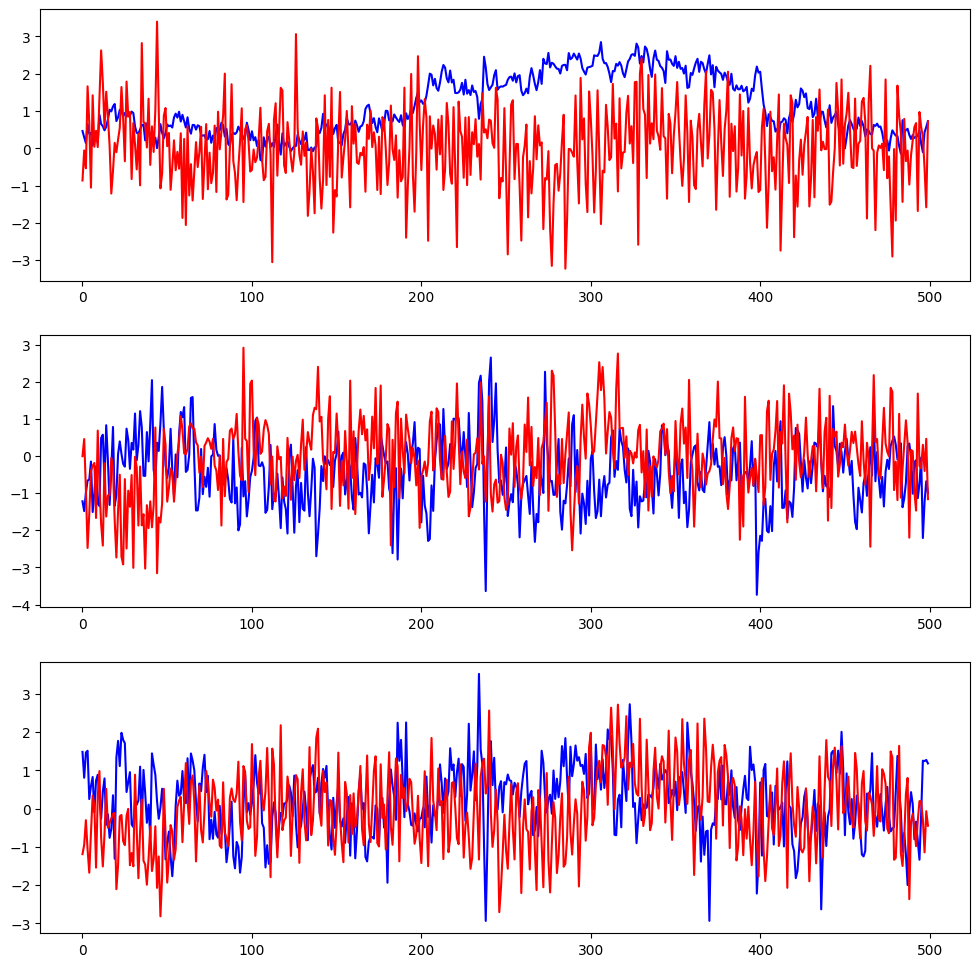

In [75]:
#apply scaling to the prediction, so we can match the scaled inputs
scaler3 = StandardScaler()
scaler3.fit(micro456_predict)
micro456_predict = scaler3.transform(micro456_predict)

fig,ax=plt.subplots(nDims456,1,figsize=(12,12))
t1 = 2000
t2 = 2500
for s in range(nDims456):
    ax[s].plot(micro456_scaled[t1:t2, s], 'b', label='target')
    ax[s].plot(micro456_predict[t1:t2, s], 'r', label='pred')
    slope, intercept, r_value, p_value, std_err = sp.stats.linregress(micro456_scaled[:,s], micro456_predict[:,s])
    print("Output %d has r %.4f and p %.4f" % (s, r_value, p_value))


In [76]:
%%shell
jupyter nbconvert --to html /content/EECS253_2025_Lecture13.ipynb

[NbConvertApp] Converting notebook /content/EECS253_2025_Lecture13.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 14 image(s).
[NbConvertApp] Writing 2517905 bytes to /content/EECS253_2025_Lecture13.html
